# EDA: House Price Data

This notebook explores the training data **exactly as `train.py` will see it** -- pulled from the mock relational database with the same SQL join used in `house_prices.db.fetch_training_data()`. The goal of EDA is to build intuition about the data and catch problems (nulls, weird ranges, obvious relationships) *before* modeling. See `../../docs/glossary.md` for a refresher on why EDA comes first.

Run `python scripts/seed_db.py` from the project root before running this notebook if `data/db/house_prices.db` doesn't exist yet.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from house_prices.db import fetch_training_data

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = fetch_training_data()
df.shape

Matplotlib is building the font cache; this may take a moment.


(2000, 10)

## 1. Shape, types, and a first look

`.info()` tells us the dtypes and, crucially, which columns have missing values (compare the `Non-Null Count` to the total row count).

In [2]:
df.head()

,property_id,sqft,bedrooms,bathrooms,year_built,lot_size,neighborhood_name,location_score,sale_price,sale_date
0,1,1392.0,1,1.0,1967,6556.483798,Riverside,0.82,430106.79,2025-06-16
1,2,2308.0,4,2.0,1964,6023.274841,Sunset District,0.74,558286.81,2025-10-28
2,3,1819.0,4,2.5,1977,7767.352908,Sunset District,0.74,543069.81,2025-01-05
3,4,1644.0,4,1.5,2016,NaN,Maple Heights,0.68,507968.11,2025-11-27
4,5,1742.0,5,3.0,2006,7454.292069,Maple Heights,0.68,556848.14,2025-10-03


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   property_id        2000 non-null   int64  
 1   sqft               2000 non-null   float64
 2   bedrooms           2000 non-null   int64  
 3   bathrooms          2000 non-null   float64
 4   year_built         2000 non-null   int64  
 5   lot_size           1834 non-null   float64
 6   neighborhood_name  2000 non-null   object 
 7   location_score     2000 non-null   float64
 8   sale_price         2000 non-null   float64
 9   sale_date          2000 non-null   object 
dtypes: float64(5), int64(3), object(2)
memory usage: 156.4+ KB


## 2. Missing values

We deliberately injected nulls into `lot_size` at the SQL level. This is exactly the kind of thing EDA should surface *before* it becomes a training-time surprise -- it's what tells us `features.py` needs an imputation strategy for this column.

In [4]:
null_summary = df.isna().sum().to_frame('null_count')
null_summary['null_rate'] = (null_summary['null_count'] / len(df)).round(3)
null_summary[null_summary['null_count'] > 0]

,null_count,null_rate
lot_size,166,0.083


## 3. Distributions and summary statistics

`.describe()` gives min/max/quartiles for every numeric column -- a fast way to spot impossible values (negative square footage, a house built in 1800, etc.) before they poison a model.

In [5]:
df.describe()

,property_id,sqft,bedrooms,bathrooms,year_built,lot_size,location_score,sale_price
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,1834.000000,2000.000000,2000.000000
mean,1000.500000,1786.168500,2.938000,2.256250,1986.692000,6451.943982,0.631490,507466.416240
std,577.494589,554.663334,1.412499,0.840574,21.282989,2196.079045,0.165323,92448.757678
min,1.000000,400.000000,1.000000,1.000000,1950.000000,1000.000000,0.350000,169736.950000
25%,500.750000,1418.000000,2.000000,1.500000,1968.000000,5039.210678,0.550000,442880.015000
50%,1000.500000,1802.000000,3.000000,2.500000,1987.000000,6355.410962,0.680000,507184.865000
75%,1500.250000,2158.000000,4.000000,3.000000,2005.000000,7955.909817,0.740000,570740.122500
max,2000.000000,3483.000000,5.000000,3.500000,2023.000000,13746.479038,0.820000,833378.510000


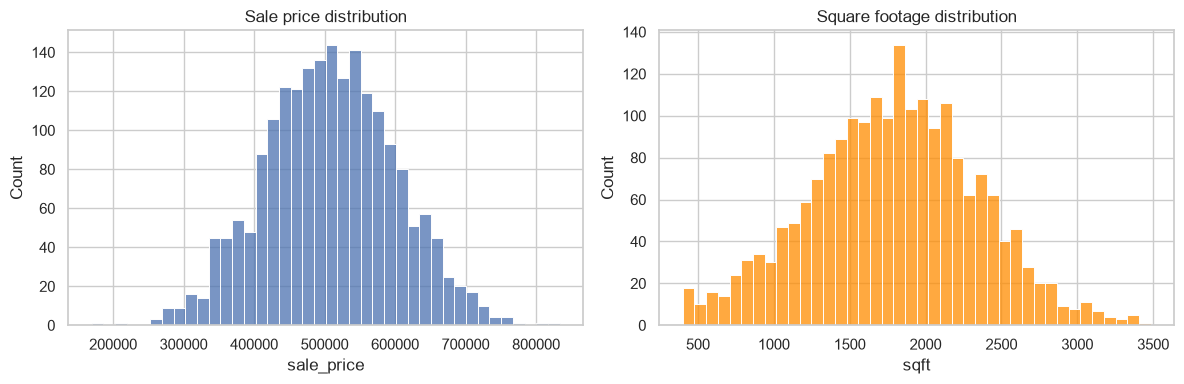

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['sale_price'], bins=40, ax=axes[0])
axes[0].set_title('Sale price distribution')
sns.histplot(df['sqft'], bins=40, ax=axes[1], color='darkorange')
axes[1].set_title('Square footage distribution')
plt.tight_layout()
plt.show()

## 4. Relationships between features and the target

A correlation heatmap is a quick (linear-relationships-only) way to see which numeric features move with `sale_price`. It won't catch non-linear relationships, but it's a good first pass.

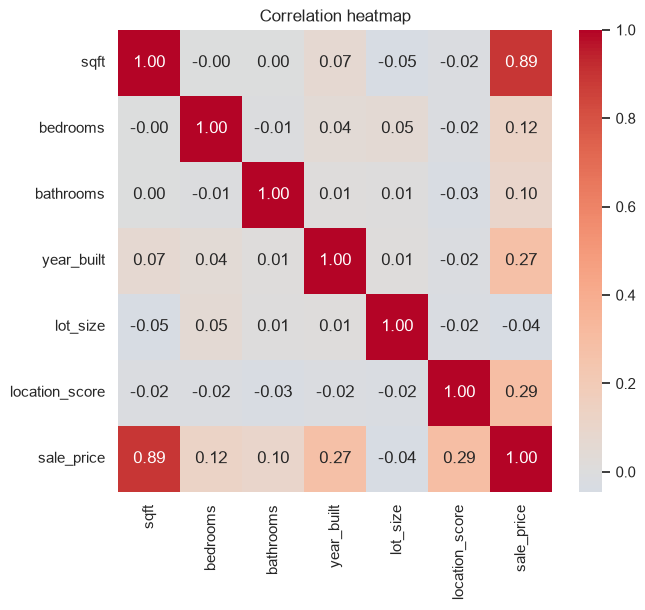

In [7]:
numeric_cols = ['sqft', 'bedrooms', 'bathrooms', 'year_built', 'lot_size', 'location_score', 'sale_price']
corr = df[numeric_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()

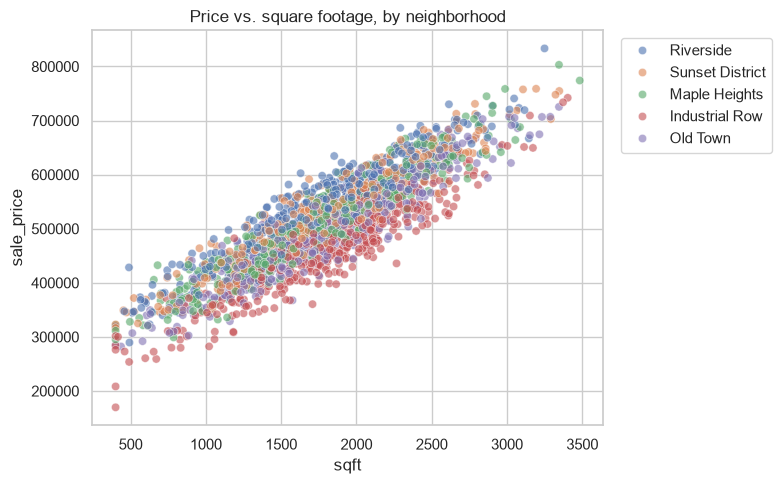

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='sqft', y='sale_price', hue='neighborhood_name', alpha=0.6)
plt.title('Price vs. square footage, by neighborhood')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

As expected from how the synthetic data is generated (see `data_generation.py`), `sqft` is strongly correlated with price, and neighborhoods with a higher `location_score` (e.g. Riverside) sit visibly above the others at the same square footage. This kind of "does this match what I'd expect" check is exactly what EDA is for -- if this *hadn't* shown up, that would be a sign something in the data generation or the SQL join is broken.

## 5. Categorical breakdown

How many rows per neighborhood, and how does price vary by neighborhood? This is what tells us one-hot encoding is the right call for `neighborhood_name` (a handful of unordered categories, none dominating) rather than, say, needing to group rare categories first.

In [9]:
df.groupby('neighborhood_name')['sale_price'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False)

,count,mean,median
neighborhood_name,,,
Riverside,419,540178.541169,547416.870
Sunset District,394,528937.823756,527306.240
Maple Heights,423,506826.769054,499559.310
Old Town,364,497695.985604,491796.180
Industrial Row,400,461618.647750,464633.695


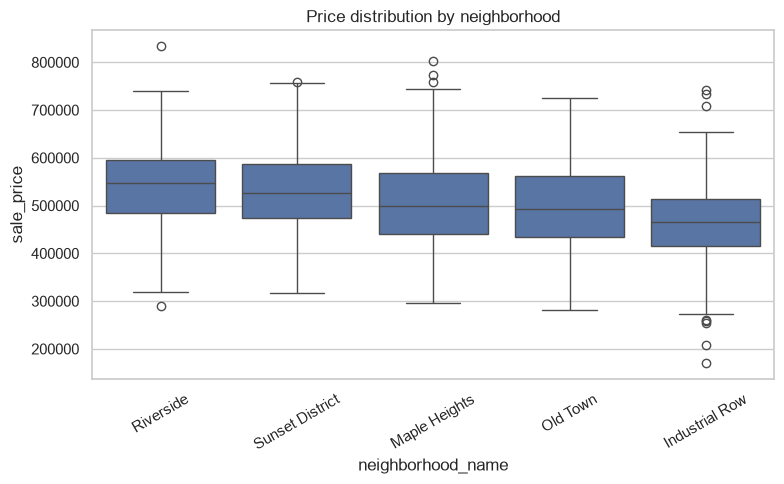

In [10]:
plt.figure(figsize=(8, 5))
order = df.groupby('neighborhood_name')['sale_price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='neighborhood_name', y='sale_price', order=order)
plt.xticks(rotation=30)
plt.title('Price distribution by neighborhood')
plt.tight_layout()
plt.show()

## Takeaways going into modeling

- `lot_size` needs imputation (~8% missing) -- handled by median imputation in `features.py`.
- `sqft`, `bedrooms`, `bathrooms`, and `location_score` all show a visible relationship with `sale_price` -- reasonable to expect even a linear model to do well here.
- `neighborhood_name` is a small, unordered set of categories -- one-hot encoding is appropriate (no natural ordering to preserve, unlike e.g. a size label).
- No obviously broken values (negative prices, absurd square footage) showed up in `.describe()` -- nothing to drop as a data-entry error.